# 03 - Feature Engineering & Data Preparation: Pemerataan Faskes Indonesia

**Tujuan notebook**
1. Audit fitur dan missing value pada `master_provinsi_clean.csv`.
2. Menangani sisa missing value (RS Khusus, Balai Kesehatan) secara eksplisit.
3. Melakukan transformasi log pada variabel yang sangat miring.
4. Mendeteksi outlier dengan median/MAD (robust z-score), terutama DKI Jakarta.
5. Menstandarkan fitur (z-score) agar siap untuk *agglomerative clustering*.
6. Menyimpan dataset siap-klaster ke `data/processed/`.

**Alur**: 02 (cleaning) -> **03 (feature engineering)** -> 04 (EDA) -> 05 (clustering).

## 0. Setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
TABLE_DIR = ROOT / "outputs" / "tables"
FIG_DIR = ROOT / "outputs" / "figures"
for d in (TABLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("ROOT      :", ROOT)
print("PROCESSED :", PROCESSED)
print("TABLE_DIR :", TABLE_DIR)

ROOT      : C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia
PROCESSED : C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\processed
TABLE_DIR : C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\outputs\tables


## 1. Load & audit dataset

In [2]:
df = pd.read_csv(PROCESSED / "master_provinsi_clean.csv")
print(f"Bentuk data: {df.shape[0]} provinsi x {df.shape[1]} kolom")
display(df.head())

Bentuk data: 38 provinsi x 44 kolom


,Provinsi,Jumlah Penduduk (Ribu),Laju Pertumbuhan Penduduk per Tahun,Persentase Penduduk,Kepadatan Penduduk per km persegi (Km2),Rasio Jenis Kelamin Penduduk,Jumlah Desa,desa_rs,desa_pkm,desa_pustu,...,pkm_needed,pkm_gap,pkm_ratio_std,pop_share,faskes_share,faskes_share_ratio,pkm_ri_share,rsk_share,rsk_missing,desa_balai_missing
0,Aceh,5695.9,1.34,1.98,100,100.9,6513,71,369,965,...,189.863333,176.136667,1.927702,1.983263,3.327444,1.677762,47.540984,10.465116,0,0
1,Sumatera Utara,15978.6,1.34,5.56,221,100.8,6113,180,620,1804,...,532.620000,86.380000,1.162179,5.563610,6.088045,1.094262,28.756058,11.057692,0,0
2,Sumatera Barat,5991.6,1.39,2.09,142,101.5,1287,70,282,729,...,199.720000,80.280000,1.401963,2.086223,2.672261,1.280909,38.571429,36.144578,0,0
3,Riau,6892.4,1.31,2.40,77,104.1,1870,68,241,1012,...,229.746667,12.253333,1.053334,2.399874,2.377797,0.990801,49.586777,17.283951,0,1
4,Jambi,3811.7,1.25,1.33,78,103.0,1586,41,209,590,...,127.056667,80.943333,1.637065,1.327201,1.862485,1.403318,47.115385,6.666667,0,1


In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "contoh": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
print("Kolom dengan missing value:")
display(audit[audit["n_missing"] > 0])

Kolom dengan missing value:


,dtype,n_missing,n_unique,contoh
desa_balai,float64,21,7,1.0
rsk,float64,6,20,9.0
total_rs,float64,6,30,86.0
rsk_share,float64,6,32,10.465116


## 2. Pemilihan fitur: tiga lensa pemerataan

Clustering memakai fitur yang mewakili tiga dimensi berbeda agar tidak sekadar mengulang indikator yang sama:

| Lensa | Fitur | Alasan |
|---|---|---|
| Akses primer per kapita | `pkm_per100k` | Ketersediaan puskesmas relatif terhadap jumlah penduduk |
| Akses sekunder per kapita | `rs_per100k` | Ketersediaan rumah sakit rujukan relatif penduduk |
| Akses geografis | `faskes_per_1000km2` | Keterjangkauan fisik (kepadatan faskes per luas) |
| Cakupan desa (primer) | `desa_pkm_pct` | Persentase desa yang memiliki puskesmas |
| Cakupan desa (sekunder) | `desa_rs_pct` | Persentase desa yang memiliki rumah sakit |

`pkm_ratio_std` **tidak dipakai** karena proporsional sempurna dengan `pkm_per100k`
(keduanya mengukur puskesmas per penduduk), sehingga tidak menambah informasi.

## 3. Penanganan missing value

In [4]:
# RS Khusus sudah diimputasi 0 pada notebook 02 dan diberi flag; cek konsistensinya.
print("Flag rsk_missing:")
print(df["rsk_missing"].value_counts(dropna=False).rename(index={False: "tidak missing", True: "missing -> diimputasi 0"}))

print("\nFlag desa_balai_missing:")
print(df["desa_balai_missing"].value_counts(dropna=False).rename(index={False: "tidak missing", True: "missing"}))

# Fitur clustering tidak memiliki missing; kolom balai tidak dipakai dalam clustering.
print("\nMissing pada fitur clustering:",
      df[["pkm_per100k", "rs_per100k", "faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]].isna().sum().to_dict())

Flag rsk_missing:
rsk_missing
tidak missing              32
missing -> diimputasi 0     6
Name: count, dtype: int64

Flag desa_balai_missing:
desa_balai_missing
missing          21
tidak missing    17
Name: count, dtype: int64

Missing pada fitur clustering: {'pkm_per100k': 0, 'rs_per100k': 0, 'faskes_per_1000km2': 0, 'desa_pkm_pct': 0, 'desa_rs_pct': 0}


**Catatan**: `desa_balai` dibiarkan missing dan tidak dipakai karena bukan bagian dari fitur
pemerataan utama. Untuk analisis lanjutan, missing ini dapat diperlakukan sebagai *missing
not at random* (balai kesehatan memang tidak ada / tidak tercatat).

## 4. Transformasi log untuk variabel miring

In [5]:
BASE_COLS = ["pkm_per100k", "rs_per100k", "faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]

skew_table = pd.DataFrame({
    "skewness": df[BASE_COLS].skew(),
    "min": df[BASE_COLS].min(),
    "max": df[BASE_COLS].max(),
})
display(skew_table.round(2))

# faskes_per_1000km2 sangat miring (DKI Jakarta ekstrem) -> log1p
df["log_faskes_per_1000km2"] = np.log1p(df["faskes_per_1000km2"])

CLUSTER_COLS = ["pkm_per100k", "rs_per100k", "log_faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]
print("Fitur final untuk clustering:", CLUSTER_COLS)

,skewness,min,max
pkm_per100k,1.05,0.41,18.44
rs_per100k,0.40,0.53,2.35
faskes_per_1000km2,5.63,0.83,359.78
desa_pkm_pct,0.98,5.54,27.40
desa_rs_pct,5.00,0.34,46.82


Fitur final untuk clustering: ['pkm_per100k', 'rs_per100k', 'log_faskes_per_1000km2', 'desa_pkm_pct', 'desa_rs_pct']


Log1p dipilih karena aman untuk nilai 0 dan meredam pengaruh ekstrem tanpa membuang
observasi. Untuk fitur lain, skew masih wajar (< 1.1) sehingga tetap memakai skala asli.

## 5. Deteksi outlier (robust z-score / MAD)

In [6]:
med = df[BASE_COLS].median()
mad = (df[BASE_COLS] - med).abs().median()
robust_z = (df[BASE_COLS] - med) / mad.replace(0, np.nan) * 1.4826

outlier_mask = (robust_z.abs() > 3.5).any(axis=1)
df["is_outlier"] = outlier_mask

print("Provinsi terdeteksi outlier (|robust z| > 3.5):")
display(df.loc[outlier_mask, ["Provinsi"] + BASE_COLS].round(2))
print(f"Jumlah provinsi outlier: {int(outlier_mask.sum())}")

print("\nJumlah provinsi ekstrem per fitur:")
display((robust_z.abs() > 3.5).sum().rename("n_provinsi_ekstrem"))

print("\nRobust z-score per provinsi (5 nilai terbesar):")
display(robust_z.abs().max(axis=1).sort_values(ascending=False).head(5).round(2))

Provinsi terdeteksi outlier (|robust z| > 3.5):


,Provinsi,pkm_per100k,rs_per100k,faskes_per_1000km2,desa_pkm_pct,desa_rs_pct
0,Aceh,6.43,1.51,7.94,5.67,1.09
2,Sumatera Barat,4.67,1.39,8.60,21.91,5.44
8,Kepulauan Bangka Belitung,4.08,1.85,5.57,16.54,6.87
9,Kepulauan Riau,4.28,1.74,16.55,22.33,6.74
10,DKI Jakarta,0.41,1.82,359.78,15.73,46.82
11,Jawa Barat,2.16,0.85,41.62,18.50,6.16
12,Jawa Tengah,2.28,0.96,36.40,10.41,3.83
13,DI Yogyakarta,3.18,2.10,63.38,27.40,15.53
14,Jawa Timur,2.30,1.04,29.50,11.54,4.46
15,Banten,2.00,1.08,41.57,16.17,7.28


Jumlah provinsi outlier: 21

Jumlah provinsi ekstrem per fitur:


pkm_per100k           9
rs_per100k            5
faskes_per_1000km2    7
desa_pkm_pct          7
desa_rs_pct           8
Name: n_provinsi_ekstrem, dtype: int64


Robust z-score per provinsi (5 nilai terbesar):


10    118.39
13     18.66
11     11.34
15     11.32
12      9.58
dtype: float64

**Interpretasi**: Data memang *heavy-tailed* — beberapa provinsi ekstrem pada fitur
berbeda. DKI Jakarta paling ekstrem pada `faskes_per_1000km2` (kepadatan faskes sangat
tinggi) dan `desa_rs_pct`, tetapi justru sangat rendah pada `pkm_per100k` karena struktur
layanan kota yang bertumpu pada RS dan klinik. Provinsi kepulauan/pedalaman juga ekstrem
pada rasio per kapita.

Outlier **tidak dibuang**; pada notebook 05 observasi dibiarkan membentuk tipe tersendiri
agar tidak mendistorsi segmentasi provinsi lain. Flag `is_outlier` disimpan untuk
keperluan uji sensitivitas.

## 6. Standardisasi z-score

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[CLUSTER_COLS])

SCALED_COLS = [
    "scaled_pkm_per100k",
    "scaled_rs_per100k",
    "scaled_log_density",
    "scaled_desa_pkm_pct",
    "scaled_desa_rs_pct",
]
scaled_df = pd.DataFrame(X_scaled, columns=SCALED_COLS, index=df.index)
df = pd.concat([df, scaled_df], axis=1)
display(df[["Provinsi"] + SCALED_COLS].head())
print("Rata-rata setelah scaling:", np.round(X_scaled.mean(axis=0), 6))
print("Std setelah scaling     :", np.round(X_scaled.std(axis=0), 6))

,Provinsi,scaled_pkm_per100k,scaled_rs_per100k,scaled_log_density,scaled_desa_pkm_pct,scaled_desa_rs_pct
0,Aceh,-0.025663,0.267718,-0.063824,-1.839670,-0.469035
1,Sumatera Utara,-0.660614,-0.214967,0.242543,-0.800393,-0.220943
2,Sumatera Barat,-0.461729,-0.021232,0.002912,1.931817,0.112777
3,Riau,-0.750894,-0.508436,-0.677170,-0.163050,-0.128388
4,Jambi,-0.266728,-0.495986,-0.405787,-0.095702,-0.269028


Rata-rata setelah scaling: [ 0.  0. -0. -0. -0.]
Std setelah scaling     : [1. 1. 1. 1. 1.]


## 7. Korelasi antarfitur

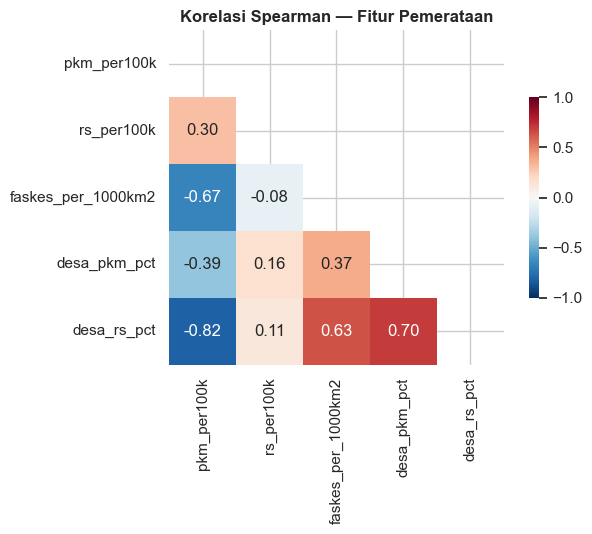

Pasangan fitur dengan |korelasi| > 0.7:
  pkm_per100k <-> desa_rs_pct: -0.82
  desa_pkm_pct <-> desa_rs_pct: 0.70


In [8]:
corr = df[BASE_COLS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, mask=mask, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Korelasi Spearman — Fitur Pemerataan", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "korelasi_fitur_clustering.png", dpi=150, bbox_inches="tight")
plt.show()

print("Pasangan fitur dengan |korelasi| > 0.7:")
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.7:
            print(f"  {corr.columns[i]} <-> {corr.columns[j]}: {corr.iloc[i, j]:.2f}")

Korelasi tinggi tidak dihindari sepenuhnya karena tiap fitur mewakili lensa berbeda
(per kapita vs cakupan desa). Namun tidak ada pasangan yang berkorelasi sempurna (>0.95),
sehingga kelima fitur tetap layak dipakai bersama dalam Ward clustering.

## 8. Simpan dataset siap analisis

In [9]:
# Dataset lengkap (raw + log + flag + scaled)
features_path = PROCESSED / "faskes_features.csv"
df.to_csv(features_path, index=False, encoding="utf-8")

# Matriks khusus clustering
cluster_matrix = df[["Provinsi"] + CLUSTER_COLS + SCALED_COLS + ["is_outlier"]].copy()
matrix_path = PROCESSED / "faskes_clustering_scaled.csv"
cluster_matrix.to_csv(matrix_path, index=False, encoding="utf-8")

# Tabel deskriptif
desc = df[BASE_COLS].describe().T
desc["skewness"] = df[BASE_COLS].skew()
desc_path = TABLE_DIR / "deskriptif_fitur.csv"
desc.to_csv(desc_path, encoding="utf-8")

print("Tersimpan:")
for p in (features_path, matrix_path, desc_path):
    print(" -", p)
display(desc.round(3))

Tersimpan:
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\processed\faskes_features.csv
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\data\processed\faskes_clustering_scaled.csv
 - C:\Users\LENOVO\OneDrive\Documents\KULIAH COYYY\SEMESTER 5\Presentasi Data & Storytelling\pemerataan-faskes-indonesia\outputs\tables\deskriptif_fitur.csv


,count,mean,std,min,25%,50%,75%,max,skewness
pkm_per100k,38.0,6.529,4.073,0.412,3.602,5.496,8.117,18.435,1.046
rs_per100k,38.0,1.394,0.437,0.533,1.052,1.298,1.746,2.347,0.400
faskes_per_1000km2,38.0,21.542,58.091,0.835,3.628,7.935,12.907,359.776,5.627
desa_pkm_pct,38.0,13.590,4.365,5.543,11.298,12.526,15.820,27.397,0.977
desa_rs_pct,38.0,4.596,7.575,0.342,1.739,2.649,4.319,46.816,4.997


## 9. Ringkasan

- 38 provinsi, tanpa missing pada fitur clustering.
- `faskes_per_1000km2` di-log karena sangat miring; DKI Jakarta tetap outlier ekstrem.
- Lima fitur final mencakup akses primer, sekunder, geografis, dan cakupan desa.
- Output: `data/processed/faskes_features.csv` dan `data/processed/faskes_clustering_scaled.csv`.

**Next**: notebook 04 memvisualisasikan sebaran dan pola regional; notebook 05 menjalankan
agglomerative clustering dan analisis ketimpangan.